# HandPD Spiral + Meander Fusion CNN (TensorFlow/Keras)
- Patients = 1, Control = 0
- Subject (පුද්ගලයා) අනුව Group K-Fold, leakage නෑ
- Fold 5ක් model save වෙනවා, inference = fold models ensemble

**මුලින් වෙනස් කරන්න ඕන තැන් දෙක:** `ZIP_PATH` සහ (අවශ්‍ය නම්) `ROOT`.

In [2]:
import os, re, glob, json, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ---------- PATHS ----------
# Notebook එක ඇති folder එකේ එක level උඩ = project root
MODEL_DIR =Path("../model")          # model files save වෙන තැන
DATA_DIR = Path("../Data")            # zip එක extract වෙන තැන
ZIP_PATH = Path("../handpd_dataset.zip")   # <-- ඔයාගේ zip path එක දාන්න

MODEL_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

# ---------- SETTINGS ----------
IMG_SIZE = 256        # CPU නම් 160 කරන්න
BATCH = 16
EPOCHS = 40
N_FOLDS = 5
SEED = 42

tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPUs:", gpus if gpus else "නෑ (CPU එකෙන් run වෙනවා)")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
print("ROOT      :", ROOT)
print("MODEL_DIR :", MODEL_DIR)

TensorFlow: 2.22.0-rc0
GPUs: නෑ (CPU එකෙන් run වෙනවා)
ROOT      : c:\Users\kanis\Desktop\model\new model one 10-18
MODEL_DIR : ..\model


## 1. Unzip සහ folders හොයාගැනීම

In [3]:
def has_dataset(base):
    return any(os.path.basename(r) == "SpiralPatients" for r, _, _ in os.walk(base))

if not has_dataset(DATA_DIR):
    assert ZIP_PATH.exists(), f"Zip file එක හම්බුණේ නෑ: {ZIP_PATH}"
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Unzip කළා.")
else:
    print("කලින්ම unzip කරලා තියෙනවා.")

def find_dir(name):
    hits = [r for r, _, _ in os.walk(DATA_DIR) if os.path.basename(r) == name]
    assert hits, f"{name} folder එක හම්බුණේ නෑ"
    return hits[0]

dirs = {n: find_dir(n) for n in
        ["SpiralPatients", "SpiralControl", "MeanderPatients", "MeanderControl"]}

def list_imgs(d):
    fs = set()
    for e in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
        fs.update(glob.glob(os.path.join(d, e)))
    return sorted(fs)

for k, v in dirs.items():
    print(k, len(list_imgs(v)))

Unzip කළා.
SpiralPatients 296
SpiralControl 72
MeanderPatients 296
MeanderControl 72


## 2. Spiral + Meander pair කිරීම (නියම ID අනුව: Meander = Spiral + 4)

In [4]:
def parse_name(fpath):
    m = re.match(r"^(\d+)-(\d+)", os.path.basename(fpath))
    assert m, f"Filename parse කරන්න බැරි වුණා: {fpath}"
    return m.group(1), int(m.group(2))

def build_pairs(spiral_dir, meander_dir, label):
    sp_map = {parse_name(f): f for f in list_imgs(spiral_dir)}
    me_map = {parse_name(f): f for f in list_imgs(meander_dir)}
    prefix = "P" if label == 1 else "H"
    rows, missing = [], 0
    for (sid, n), sp_path in sorted(sp_map.items()):
        key = (sid, n + 4)
        if key in me_map:
            rows.append((sp_path, me_map[key], label, f"{prefix}{sid}"))
        else:
            missing += 1
    print(f"label={label}: pairs={len(rows)}, unmatched spiral={missing}")
    return rows

rows = build_pairs(dirs["SpiralPatients"], dirs["MeanderPatients"], 1) + \
       build_pairs(dirs["SpiralControl"],  dirs["MeanderControl"],  0)

df = pd.DataFrame(rows, columns=["spiral", "meander", "label", "subject"])
print(df.shape, df.label.value_counts().to_dict())
print("subjects:", df.groupby("label").subject.nunique().to_dict())
print("images per subject:", df.groupby("subject").size().value_counts().to_dict())

label=1: pairs=296, unmatched spiral=0
label=0: pairs=72, unmatched spiral=0
(368, 4) {1: 296, 0: 72}
subjects: {0: 18, 1: 74}
images per subject: {4: 92}


## 3. Images load කිරීම (grayscale + invert: ඉරි = දීප්තිමත්, background = 0)

(368, 256, 256, 1) (368, 256, 256, 1) (368,)


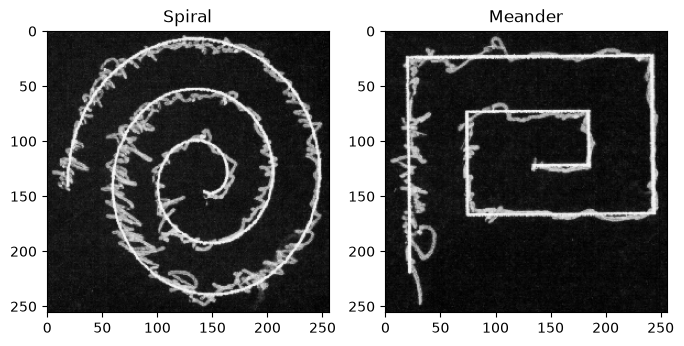

In [5]:
def load_np(path):
    img = tf.keras.utils.load_img(path, color_mode="grayscale",
                                  target_size=(IMG_SIZE, IMG_SIZE))
    a = tf.keras.utils.img_to_array(img) / 255.0
    return (1.0 - a).astype("float32")

X_sp = np.stack([load_np(p) for p in df.spiral])
X_me = np.stack([load_np(p) for p in df.meander])
y_all = df.label.values.astype("float32")
print(X_sp.shape, X_me.shape, y_all.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(X_sp[0, :, :, 0], cmap="gray"); ax[0].set_title("Spiral")
ax[1].imshow(X_me[0, :, :, 0], cmap="gray"); ax[1].set_title("Meander")
plt.show()

## 4. Augmentation, tf.data, model

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

augment = tf.keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant", fill_value=0.0),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=0.0),
])

def aug_pair(x, y):
    a, b = x
    return (augment(a, training=True), augment(b, training=True)), y

def make_ds(idx, training):
    ds = tf.data.Dataset.from_tensor_slices(((X_sp[idx], X_me[idx]), y_all[idx]))
    if training:
        ds = ds.shuffle(len(idx), seed=SEED).map(aug_pair, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

def conv_branch(name):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 1), name=f"{name}_input")
    x = inp
    for f in [16, 32, 64, 64, 128]:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x)   # momentum අඩු: inference stats ඉක්මනින් settle
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    g = layers.Concatenate()([layers.GlobalAveragePooling2D()(x),
                              layers.GlobalMaxPooling2D()(x)])
    return inp, g

def build_model(steps_per_epoch, epochs):
    sp_in, sp_f = conv_branch("spiral")
    me_in, me_f = conv_branch("meander")
    x = layers.Concatenate()([sp_f, me_f])
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model([sp_in, me_in], out, name="spiral_meander_fusion")
    lr = tf.keras.optimizers.schedules.CosineDecay(5e-4, steps_per_epoch * epochs)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0),
              loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

build_model(10, 1).summary()

Model: "spiral_meander_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spiral_input        │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_input       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        144 │ spiral_input[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 256, 256,  │        144 │ meander_input[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │         64 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 128, 128,  │          0 │ re_lu_5[0][0]     │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      4,608 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │      4,608 │ max_pooling2d_5[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_1[0][0]   

 Total params: 302,881 (1.16 MB)

 Trainable params: 301,665 (1.15 MB)

 Non-trainable params: 1,216 (4.75 KB)

## 5. Stratified Group 5-Fold CV
- හැම fold එකකම threshold එක **train set එකේ (inference mode) Youden** එකෙන් තෝරනවා
- Score = logit(p) - logit(threshold) → fold අතර probability scale වෙනස් වුණත් pooled metrics හරි යනවා
- Fold models `model/` folder එකට save වෙනවා

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve

def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    t = thr[np.argmax(tpr - fpr)]
    return float(np.clip(t, 1e-6, 1 - 1e-6))

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_prob  = np.zeros(len(df))
oof_score = np.zeros(len(df))
oof_fold  = np.zeros(len(df), dtype=int)
fold_thr, fold_aucs = [], []

for fold, (tr, te) in enumerate(sgkf.split(df, df.label, groups=df.subject)):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold)
    t0 = time.time()

    n0 = (y_all[tr] == 0).sum(); n1 = (y_all[tr] == 1).sum()
    cw = {0: len(tr) / (2 * n0), 1: len(tr) / (2 * n1)}

    steps = int(np.ceil(len(tr) / BATCH))
    model = build_model(steps, EPOCHS)

    log = tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda e, l: print(
            f"  epoch {e+1:>2}/{EPOCHS} loss={l['loss']:.3f} auc={l['auc']:.3f}") if (e + 1) % 10 == 0 else None)
    model.fit(make_ds(tr, True), epochs=EPOCHS, class_weight=cw, verbose=0, callbacks=[log])

    # inference mode predictions
    p_tr = model.predict(make_ds(tr, False), verbose=0).ravel()
    p_te = model.predict(make_ds(te, False), verbose=0).ravel()

    thr = youden_threshold(y_all[tr], p_tr)
    oof_prob[te]  = p_te
    oof_score[te] = logit(p_te) - logit(thr)
    oof_fold[te]  = fold + 1
    fold_thr.append(thr)

    auc_tr = roc_auc_score(y_all[tr], p_tr)
    auc_te = roc_auc_score(y_all[te], p_te)
    fold_aucs.append(auc_te)
    print(f"Fold {fold+1}: train_AUC={auc_tr:.3f} | test_AUC={auc_te:.3f} | thr={thr:.3f} | "
          f"mean prob control={p_te[y_all[te]==0].mean():.3f} patient={p_te[y_all[te]==1].mean():.3f} | "
          f"{time.time()-t0:.0f}s")

    model.save(MODEL_DIR / f"fold{fold+1}.keras")

print("\nFold AUC mean ± std:", np.mean(fold_aucs).round(3), "±", np.std(fold_aucs).round(3))
print("OOF AUC (raw prob)         :", round(roc_auc_score(y_all, oof_prob), 3))
print("OOF AUC (normalized score) :", round(roc_auc_score(y_all, oof_score), 3))

c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  epoch 10/40 loss=0.500 auc=0.836
  epoch 20/40 loss=0.407 auc=0.892
  epoch 30/40 loss=0.236 auc=0.968
  epoch 40/40 loss=0.204 auc=0.979
Fold 1: train_AUC=0.973 | test_AUC=0.876 | thr=0.981 | mean prob control=0.807 patient=0.986 | 689s


c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  epoch 10/40 loss=0.520 auc=0.831
  epoch 20/40 loss=0.381 auc=0.916
  epoch 30/40 loss=0.292 auc=0.948
  epoch 40/40 loss=0.247 auc=0.970
Fold 2: train_AUC=0.971 | test_AUC=0.917 | thr=0.992 | mean prob control=0.933 patient=0.995 | 679s


c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


...

c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  epoch 10/40 loss=0.391 auc=0.903
  epoch 20/40 loss=0.234 auc=0.967
  epoch 30/40 loss=0.178 auc=0.982
  epoch 40/40 loss=0.254 auc=0.962
Fold 4: train_AUC=0.985 | test_AUC=0.494 | thr=0.391 | mean prob control=0.783 patient=0.865 | 693s


c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  epoch 10/40 loss=0.550 auc=0.795
  epoch 20/40 loss=0.360 auc=0.922
  epoch 30/40 loss=0.317 auc=0.941
  epoch 40/40 loss=0.350 auc=0.927
Fold 5: train_AUC=0.967 | test_AUC=0.989 | thr=0.997 | mean prob control=0.937 patient=0.999 | 744s

Fold AUC mean ± std: 0.848 ± 0.181


AttributeError: 'float' object has no attribute 'round'

In [11]:
folds = list(sgkf.split(df, df.label, groups=df.subject))
tr, te = folds[3]                      # Fold 4
subj_te, y_te = df.subject.values[te], y_all[te]

n0 = (y_all[tr] == 0).sum(); n1 = (y_all[tr] == 1).sum()
cw = {0: len(tr) / (2 * n0), 1: len(tr) / (2 * n1)}
steps = int(np.ceil(len(tr) / BATCH))

for seed in [1, 2, 3]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    m = build_model(steps, EPOCHS)
    m.fit(make_ds(tr, True), epochs=EPOCHS, class_weight=cw, verbose=0)

    p_tr = m.predict(make_ds(tr, False), verbose=0).ravel()
    p_te = m.predict(make_ds(te, False), verbose=0).ravel()
    thr = youden_threshold(y_all[tr], p_tr)
    s = logit(p_te) - logit(thr)

    print(f"\nSeed {seed}: test_AUC={roc_auc_score(y_te, p_te):.3f} | thr={thr:.3f}")
    print(pd.Series(s[y_te == 0], index=subj_te[y_te == 0]).groupby(level=0).mean().round(2).to_string())

c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Seed 1: test_AUC=0.492 | thr=0.989
H0287    0.74
H0297    3.17
H0305    7.75


c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Seed 2: test_AUC=0.669 | thr=0.326
H0287   -2.39
H0297    2.27
H0305    6.70


c:\Users\kanis\Desktop\model\new model one 10-18\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Seed 3: test_AUC=0.433 | thr=0.995
H0287    0.47
H0297    4.78
H0305    9.21


In [8]:
print("Fold AUC mean ± std:", round(np.mean(fold_aucs), 3), "±", round(np.std(fold_aucs), 3))
print("OOF AUC (raw prob)         :", round(roc_auc_score(y_all, oof_prob), 3))
print("OOF AUC (normalized score) :", round(roc_auc_score(y_all, oof_score), 3))

# Fold එකෙන් fold එකට විස්තර
for f in range(1, N_FOLDS + 1):
    m = oof_fold == f
    y, s = y_all[m], oof_score[m]
    print(f"Fold {f}: AUC={roc_auc_score(y, s):.3f} | "
          f"control subjects={df[m & (y_all==0)].subject.nunique()} | "
          f"control සාර්ථක={((s<=0)&(y==0)).sum()}/{(y==0).sum()} | "
          f"patient සාර්ථක={((s>0)&(y==1)).sum()}/{(y==1).sum()}")

# Fold 4 එකේ control පුද්ගලයෙක් බැගින් score එක
m4 = (oof_fold == 4) & (y_all == 0)
print("\nFold 4 control subjects (mean score, >0 = වැරදියට Patient කියලා):")
print(pd.Series(oof_score[m4], index=df.subject[m4]).groupby(level=0).mean().round(2))

Fold AUC mean ± std: 0.848 ± 0.181
OOF AUC (raw prob)         : 0.814
OOF AUC (normalized score) : 0.839
Fold 1: AUC=0.876 | control subjects=4 | control සාර්ථක=13/16 | patient සාර්ථක=54/60
Fold 2: AUC=0.917 | control subjects=4 | control සාර්ථක=13/16 | patient සාර්ථක=53/60
Fold 3: AUC=0.965 | control subjects=3 | control සාර්ථක=12/12 | patient සාර්ථක=50/60
Fold 4: AUC=0.494 | control subjects=3 | control සාර්ථක=2/12 | patient සාර්ථක=54/60
Fold 5: AUC=0.989 | control subjects=4 | control සාර්ථක=15/16 | patient සාර්ථක=49/56

Fold 4 control subjects (mean score, >0 = වැරදියට Patient කියලා):
subject
H0287   -0.10
H0297    4.48
H0305    7.67
dtype: float64


## 6. Final metrics (score > 0 = Patient)

In [12]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score)

pred = (oof_score > 0).astype(int)
print(confusion_matrix(y_all, pred))
print(classification_report(y_all, pred, target_names=["Control", "Patient"], zero_division=0))
print("Balanced accuracy:", round(balanced_accuracy_score(y_all, pred), 3))
print("Macro F1         :", round(f1_score(y_all, pred, average="macro"), 3))

[[ 55  17]
 [ 36 260]]
              precision    recall  f1-score   support

     Control       0.60      0.76      0.67        72
     Patient       0.94      0.88      0.91       296

    accuracy                           0.86       368
   macro avg       0.77      0.82      0.79       368
weighted avg       0.87      0.86      0.86       368

Balanced accuracy: 0.821
Macro F1         : 0.791


## 7. Config save + අලුත් images වලට predict කිරීම (fold ensemble)

In [13]:
config = {"img_size": IMG_SIZE, "fold_thresholds": fold_thr,
          "label_map": {"0": "Control", "1": "Patient"},
          "note": "score = mean_k(logit(p_k) - logit(thr_k)); score > 0 => Patient"}
with open(MODEL_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

def predict_pair(spiral_path, meander_path):
    cfg = json.load(open(MODEL_DIR / "config.json"))
    size = cfg["img_size"]

    def prep(p):
        img = tf.keras.utils.load_img(p, color_mode="grayscale", target_size=(size, size))
        a = tf.keras.utils.img_to_array(img) / 255.0
        return (1.0 - a).astype("float32")[None]

    xs, xm = prep(spiral_path), prep(meander_path)
    scores = []
    for k, thr in enumerate(cfg["fold_thresholds"], start=1):
        m = tf.keras.models.load_model(MODEL_DIR / f"fold{k}.keras")
        p = float(m.predict([xs, xm], verbose=0).ravel()[0])
        scores.append(logit(np.array(p)) - logit(np.array(thr)))
    s = float(np.mean(scores))
    return {"score": s, "prediction": "Patient" if s > 0 else "Control"}

# උදාහරණයක් (dataset එකේ පළමු pair එක):
print(predict_pair(df.spiral[0], df.meander[0]), "| true label:", int(df.label[0]))

{'score': 4.475417621513818, 'prediction': 'Patient'} | true label: 1


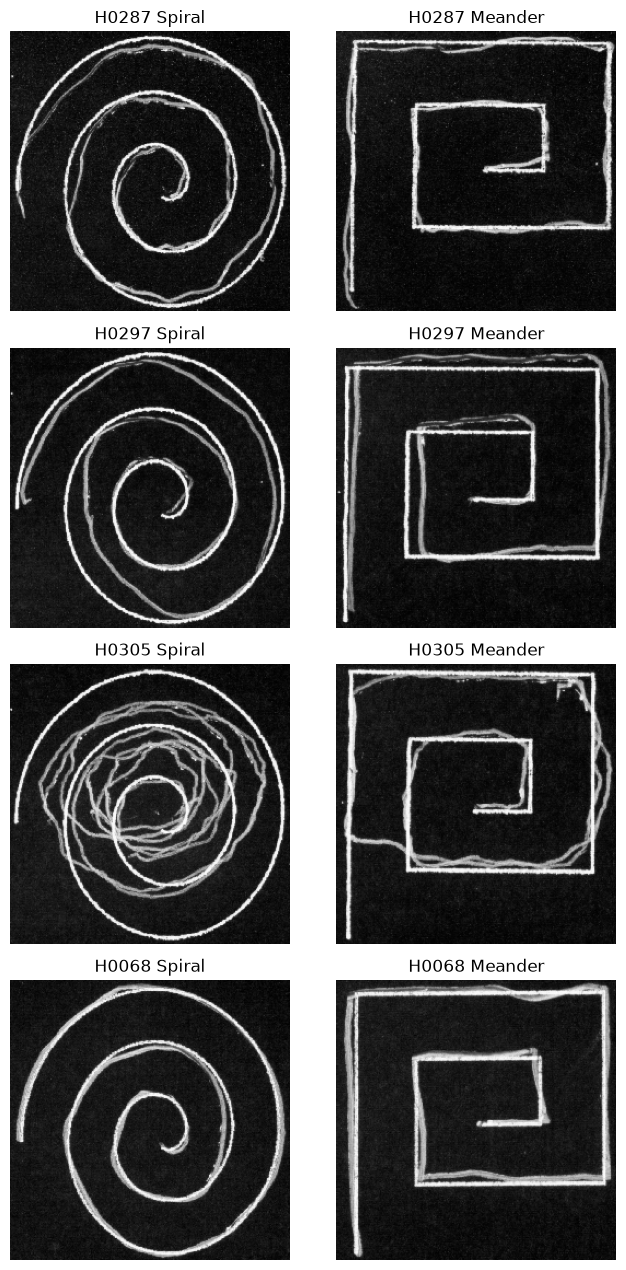

In [14]:
subs = ["H0287", "H0297", "H0305",
        df[(df.label == 0) & (oof_fold == 5)].subject.iloc[0]]   # හරියට හඳුනාගත් control එකක් (සංසන්දනයට)

fig, ax = plt.subplots(len(subs), 2, figsize=(7, 3.2 * len(subs)))
for r, sid in enumerate(subs):
    i = df.index[df.subject == sid][0]
    ax[r, 0].imshow(X_sp[i, :, :, 0], cmap="gray"); ax[r, 0].set_title(f"{sid} Spiral")
    ax[r, 1].imshow(X_me[i, :, :, 0], cmap="gray"); ax[r, 1].set_title(f"{sid} Meander")
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()